In [1]:
import sys; sys.path.append("..")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import PROCESSED_DIR
from src.preprocessing import build_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

In [2]:
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
X_test  = pd.read_parquet(PROCESSED_DIR / "X_test.parquet")
y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["readmitted_30"]
y_test  = pd.read_parquet(PROCESSED_DIR / "y_test.parquet")["readmitted_30"]
groups_train = pd.read_parquet(PROCESSED_DIR / "groups_train.parquet")["patient_nbr"]
print(X_train.shape, X_test.shape)    # (69613, 44) (29727, 44)

(69613, 44) (29727, 44)


In [3]:
print(X_train.head())

                         race  gender  age  admission_type_id  \
encounter_id                                                    
149190              Caucasian       0    2                  1   
64410         AfricanAmerican       0    3                  1   
500364              Caucasian       1    4                  1   
16680               Caucasian       1    5                  1   
35754               Caucasian       1    6                  2   

              discharge_disposition_id  admission_source_id  time_in_hospital  \
encounter_id                                                                    
149190                               1                    7                 3   
64410                                1                    7                 2   
500364                               1                    7                 2   
16680                                1                    7                 1   
35754                                1                    

In [4]:
def center(X):
    mu=X.mean(axis=0)
    return X-mu , mu

def covariance_matrix(x_center):
    n=x_center.shape[0]
    return (x_center.T @ x_center)/(n-1)


In [5]:
def pca_fit(X,k):
    Xc, mu = center(X)
    C = covariance_matrix(Xc)
    vals, vecs = np.linalg.eigh(C)
    idx = np.argsort(vals)[::-1]
    vals = vals[idx]
    vecs = vecs[:, idx]
    return {
        "mean": mu,
        "components": vecs[:, :k],
        "explained_variance": vals[:k],
        "explained_variance_ratio": vals[:k] / np.sum(vals),
    }

In [6]:
def pca_transform(X, model):
    return (X - model["mean"]) @ model["components"]

In [7]:
pre_scale = Pipeline([("pre", build_preprocessor())])
Xs_train = pre_scale.fit_transform(X_train)      # fit on train only
print(Xs_train.shape)

(69613, 138)


80% of variance needs 23 components
90% of variance needs 36 components
95% of variance needs 51 components
99% of variance needs 83 components
k95: 51


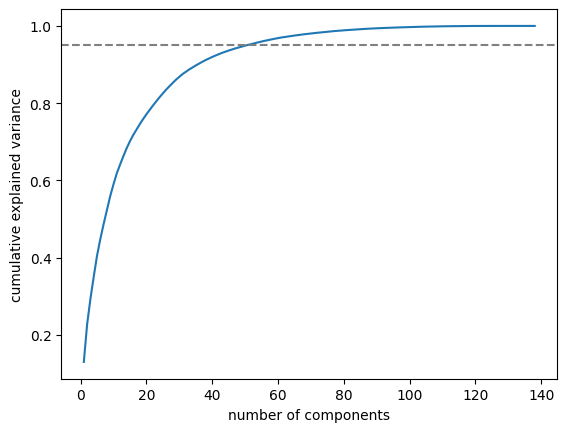

In [8]:
full = pca_fit(Xs_train, k=Xs_train.shape[1])
evr = full["explained_variance_ratio"]
cum = np.cumsum(evr)
for target in (0.80, 0.90, 0.95, 0.99):
    print(f"{int(target*100)}% of variance needs {int(np.searchsorted(cum, target) + 1)} components")

k95 = int(np.searchsorted(cum, 0.95) + 1)
print("k95:", k95)

plt.plot(range(1, len(cum) + 1), cum)
plt.axhline(0.95, ls="--", color="gray")
plt.xlabel("number of components"); plt.ylabel("cumulative explained variance"); plt.show()

In [9]:
model   = pca_fit(Xs_train, k95)
Z_train = pca_transform(Xs_train, model)

In [10]:
clf = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42).fit(Z_train, y_train)
